# Encoder-only Transformer Forecast: USD/EUR

Notebook นี้ใช้เฉพาะ **Transformer Encoder** สำหรับพยากรณ์ราคา observation ถัดไป ไม่มี Decoder, cross-attention, teacher forcing หรือ autoregressive token generation

```text
ตรวจและ Clean ข้อมูล
→ สร้าง Time-series Features
→ สร้าง Sequence Windows
→ แบ่งข้อมูลตามเวลา
→ Scaling เฉพาะ Train
→ Transformer Encoder
→ Regression Head
→ Expanding-window Cross-validation
→ เลือก Hyperparameters
→ Train และ Early Stopping
→ Locked Test
→ เปรียบเทียบ Naive Baseline
→ Residual และ Attention Diagnostics
→ Fit Final Model
→ Forecast observation ถัดไป
```

โจทย์: ใช้ sequence ที่สิ้นสุด ณ เวลา `t` เพื่อทำนาย `Price[t+1]` แบบ rolling one-step-ahead โดยไม่ shuffle ข้อมูล


## 1) Environment และ Reproducibility

กำหนด random seed และใช้ TensorFlow/Keras สร้างโมเดลขนาดเล็กให้เหมาะกับข้อมูลประมาณหนึ่งพัน observations


In [1]:
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import random
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from scipy import stats
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
CV_SPLITS = 3
MAX_EPOCHS = 40
PATIENCE = 5
DATA_PATH = Path(
    r"C:\Users\User\Desktop\vs_nine\Project_stat\USD_EUR Historical Data.csv"
)


def reset_seeds(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


reset_seeds()
print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))
print("Data path:", DATA_PATH)

TensorFlow version: 2.21.0


GPU devices: []
Data path: C:\Users\User\Desktop\vs_nine\Project_stat\USD_EUR Historical Data.csv


## 2) ตรวจและ Clean ข้อมูล

แปลงวันที่และราคา ลบเฉพาะข้อมูลที่ใช้ไม่ได้/วันที่ซ้ำ เรียงจากอดีตไปอนาคต ไม่เติมวันหยุดตลาด ไม่ลบ spikes อัตโนมัติ และไม่ใช้ `Vol.` เพราะ missing สูง


In [2]:
def load_and_clean_data(path):
    raw_df = pd.read_csv(path)
    df = raw_df.copy()
    df["Date"] = pd.to_datetime(
        df["Date"],
        format="%m/%d/%Y",
        errors="coerce",
    )

    for column in ["Price", "Open", "High", "Low"]:
        df[column] = pd.to_numeric(
            df[column].astype(str).str.replace(",", "", regex=False),
            errors="coerce",
        )

    quality = pd.Series(
        {
            "raw_rows": len(raw_df),
            "invalid_dates": int(df["Date"].isna().sum()),
            "invalid_prices": int(df["Price"].isna().sum()),
            "duplicate_dates": int(df["Date"].duplicated().sum()),
            "volume_missing_pct": round(df["Vol."].isna().mean() * 100, 2),
        },
        name="value",
    )

    df = (
        df.dropna(subset=["Date", "Price"])
        .drop_duplicates(subset=["Date"], keep="last")
        .sort_values("Date")
        .set_index("Date")
    )
    market_df = df[["Price", "Open", "High", "Low"]].copy()
    market_df[["Open", "High", "Low"]] = market_df[
        ["Open", "High", "Low"]
    ].ffill()
    return raw_df, market_df, quality


raw_df, market_df, data_quality = load_and_clean_data(DATA_PATH)
display(data_quality.to_frame())
display(market_df.head())
display(market_df.tail())
print(f"Clean rows: {len(market_df):,}")
print(f"Period: {market_df.index.min().date()} to {market_df.index.max().date()}")

,value
raw_rows,1044.00
invalid_dates,0.00
invalid_prices,0.00
duplicate_dates,0.00
volume_missing_pct,85.73


,Price,Open,High,Low
Date,,,,
2022-07-01,0.9589,0.9541,0.9647,0.9536
2022-07-04,0.9594,0.9593,0.9601,0.9557
2022-07-05,0.9739,0.9598,0.9771,0.9570
2022-07-06,0.9822,0.9739,0.9842,0.9731
2022-07-07,0.9842,0.9822,0.9859,0.9783


,Price,Open,High,Low
Date,,,,
2026-06-25,0.8796,0.8802,0.8824,0.8781
2026-06-26,0.8784,0.8795,0.8808,0.8745
2026-06-29,0.8756,0.8779,0.8789,0.8748
2026-06-30,0.8756,0.8756,0.8786,0.8743
2026-07-01,0.8790,0.8756,0.8802,0.8752


Clean rows: 1,044
Period: 2022-07-01 to 2026-07-01


### ตรวจแนวโน้มราคาและ Log Return

กราฟใช้ตรวจ trend, regime และ volatility โดยไม่ใช้ Test เพื่อย้อนกลับไปแก้การแบ่งข้อมูล


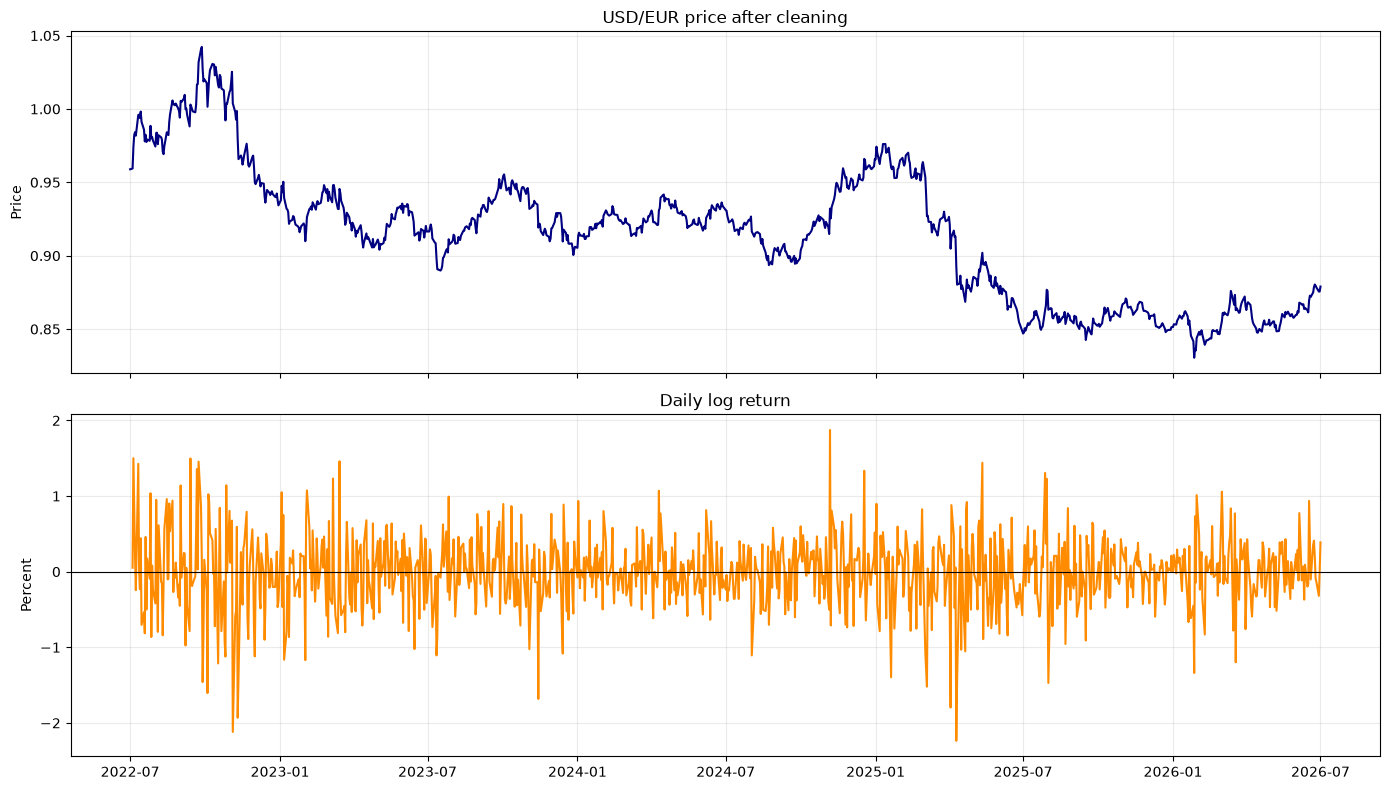

In [3]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
axes[0].plot(market_df.index, market_df["Price"], color="navy")
axes[0].set_title("USD/EUR price after cleaning")
axes[0].set_ylabel("Price")
axes[0].grid(alpha=0.25)

log_return = np.log(market_df["Price"]).diff() * 100
axes[1].plot(market_df.index, log_return, color="darkorange")
axes[1].axhline(0, color="black", linewidth=0.8)
axes[1].set_title("Daily log return")
axes[1].set_ylabel("Percent")
axes[1].grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 3) Features, Target และ Sequence Windows

หนึ่ง token คือข้อมูลตลาดหนึ่ง observation ซึ่งประกอบด้วย OHLC, returns, range, rolling statistics และ cyclic day-of-week features

หนึ่ง sample ใช้ `[t-lookback+1, ..., t]` เพื่อทำนาย `Price[t+1]` ดังนั้นทุก token เป็นอดีตเมื่อเทียบกับ target และไม่มี target leakage


In [4]:
FEATURE_COLUMNS = [
    "Price",
    "Open",
    "High",
    "Low",
    "return_1",
    "log_return_1",
    "range_1",
    "open_close_1",
    "rolling_mean_5",
    "rolling_std_5",
    "rolling_mean_10",
    "rolling_std_10",
    "day_sin",
    "day_cos",
]


def engineer_features(source_df):
    frame = source_df.copy()
    frame["return_1"] = frame["Price"].pct_change(fill_method=None)
    frame["log_return_1"] = np.log(frame["Price"]).diff()
    frame["range_1"] = frame["High"] - frame["Low"]
    frame["open_close_1"] = frame["Price"] - frame["Open"]
    frame["rolling_mean_5"] = frame["Price"].rolling(5).mean()
    frame["rolling_std_5"] = frame["Price"].rolling(5).std()
    frame["rolling_mean_10"] = frame["Price"].rolling(10).mean()
    frame["rolling_std_10"] = frame["Price"].rolling(10).std()
    frame["day_sin"] = np.sin(2 * np.pi * frame.index.dayofweek / 5)
    frame["day_cos"] = np.cos(2 * np.pi * frame.index.dayofweek / 5)
    return frame.dropna(subset=FEATURE_COLUMNS)


def make_sequences(feature_frame, lookback):
    values = feature_frame[FEATURE_COLUMNS].to_numpy(dtype=np.float32)
    prices = feature_frame["Price"].to_numpy(dtype=np.float32)
    dates = feature_frame.index.to_numpy()
    X, y, target_dates, previous_prices = [], [], [], []

    for target_index in range(lookback, len(feature_frame)):
        X.append(values[target_index - lookback:target_index])
        y.append(prices[target_index])
        target_dates.append(dates[target_index])
        previous_prices.append(prices[target_index - 1])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32),
        pd.DatetimeIndex(target_dates),
        np.asarray(previous_prices, dtype=np.float32),
    )


feature_frame = engineer_features(market_df)
example_X, example_y, example_dates, example_previous = make_sequences(
    feature_frame,
    lookback=20,
)
print("Feature columns:", FEATURE_COLUMNS)
print("Example X shape:", example_X.shape)
print("Example y shape:", example_y.shape)
print("First target date:", example_dates[0].date())
print("Last input price -> target:", example_previous[0], "->", example_y[0])

Feature columns: ['Price', 'Open', 'High', 'Low', 'return_1', 'log_return_1', 'range_1', 'open_close_1', 'rolling_mean_5', 'rolling_std_5', 'rolling_mean_10', 'rolling_std_10', 'day_sin', 'day_cos']
Example X shape: (1015, 20, 14)
Example y shape: (1015,)
First target date: 2022-08-11
Last input price -> target: 0.971 -> 0.9692


## 4) Chronological Splits

เปรียบเทียบ 80/20 และ 70/15/15 โดยไม่ shuffle ข้อมูล Test ถูกล็อกไว้จนเลือก architecture และจำนวน epochs เสร็จ


In [5]:
n = len(feature_frame)
split_80_position = int(n * 0.80)
split_70_position = int(n * 0.70)
split_85_position = int(n * 0.85)

test_start_20 = feature_frame.index[split_80_position]
validation_start_15 = feature_frame.index[split_70_position]
test_start_15 = feature_frame.index[split_85_position]

split_summary = pd.DataFrame(
    [
        {
            "Strategy": "80/20",
            "Train end": feature_frame.index[split_80_position - 1].date(),
            "Validation": "CV + internal holdout inside train",
            "Test start": test_start_20.date(),
            "Test end": feature_frame.index.max().date(),
        },
        {
            "Strategy": "70/15/15",
            "Train end": feature_frame.index[split_70_position - 1].date(),
            "Validation start": validation_start_15.date(),
            "Validation end": feature_frame.index[split_85_position - 1].date(),
            "Test start": test_start_15.date(),
            "Test end": feature_frame.index.max().date(),
        },
    ]
)
display(split_summary)

,Strategy,Train end,Validation,Test start,Test end,Validation start,Validation end
0,80/20,2025-09-15,CV + internal holdout inside train,2025-09-16,2026-07-01,NaN,NaN
1,70/15/15,2025-04-22,NaN,2025-11-26,2026-07-01,2025-04-23,2025-11-25


## 5) Encoder-only Transformer Architecture

```text
Historical sequence
→ Dense input projection
→ Learned positional encoding
→ Self-attention + residual + LayerNorm
→ Feed-forward + residual + LayerNorm
→ Last-token หรือ Average pooling
→ Dense regression head
→ Price[t+1]
```

ไม่มี Decoder ทุก configuration และไม่ต้องใช้ causal mask เพราะ input window ทั้งหมดอยู่ก่อน target


In [6]:
class LearnedPositionalEncoding(layers.Layer):
    """Trainable positional vectors added to projected input tokens."""

    def build(self, input_shape):
        self.position_vectors = self.add_weight(
            name="position_vectors",
            shape=(1, input_shape[1], input_shape[2]),
            initializer=keras.initializers.RandomNormal(stddev=0.02),
            trainable=True,
        )

    def call(self, inputs):
        return inputs + self.position_vectors


def build_encoder_model(config, n_features):
    """Encoder-only Transformer followed by a scalar regression head."""
    inputs = keras.Input(
        shape=(config["lookback"], n_features),
        name="historical_sequence",
    )
    x = layers.Dense(config["d_model"], name="input_projection")(inputs)
    x = LearnedPositionalEncoding(name="positional_encoding")(x)
    last_attention_scores = None

    for block_index in range(config["num_blocks"]):
        attention_output, last_attention_scores = layers.MultiHeadAttention(
            num_heads=config["num_heads"],
            key_dim=config["d_model"] // config["num_heads"],
            dropout=config["dropout"],
            name=f"self_attention_{block_index + 1}",
        )(x, x, return_attention_scores=True)
        attention_output = layers.Dropout(config["dropout"])(attention_output)
        x = layers.LayerNormalization(epsilon=1e-6)(x + attention_output)

        feed_forward = layers.Dense(
            config["ff_dim"],
            activation="gelu",
        )(x)
        feed_forward = layers.Dropout(config["dropout"])(feed_forward)
        feed_forward = layers.Dense(config["d_model"])(feed_forward)
        x = layers.LayerNormalization(epsilon=1e-6)(x + feed_forward)

    if config["pooling"] == "last":
        x = layers.Lambda(lambda tensor: tensor[:, -1, :], name="last_token")(x)
    else:
        x = layers.GlobalAveragePooling1D(name="average_pooling")(x)

    x = layers.Dense(config["d_model"], activation="relu")(x)
    x = layers.Dropout(config["dropout"])(x)
    output = layers.Dense(1, name="next_price")(x)

    model = keras.Model(inputs, output, name="encoder_only_transformer")
    attention_model = keras.Model(
        inputs,
        last_attention_scores,
        name="attention_inspector",
    )
    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=config["learning_rate"],
            clipnorm=1.0,
        ),
        loss=keras.losses.Huber(),
        metrics=[keras.metrics.RootMeanSquaredError(name="rmse")],
    )
    return model, attention_model


TRANSFORMER_CONFIGS = [
    {
        "lookback": 10,
        "d_model": 16,
        "num_heads": 2,
        "ff_dim": 32,
        "num_blocks": 1,
        "dropout": 0.10,
        "pooling": "last",
        "learning_rate": 0.001,
        "batch_size": 32,
    },
    {
        "lookback": 20,
        "d_model": 16,
        "num_heads": 2,
        "ff_dim": 32,
        "num_blocks": 1,
        "dropout": 0.10,
        "pooling": "last",
        "learning_rate": 0.001,
        "batch_size": 32,
    },
    {
        "lookback": 30,
        "d_model": 16,
        "num_heads": 2,
        "ff_dim": 32,
        "num_blocks": 1,
        "dropout": 0.10,
        "pooling": "last",
        "learning_rate": 0.001,
        "batch_size": 32,
    },
    {
        "lookback": 20,
        "d_model": 32,
        "num_heads": 4,
        "ff_dim": 64,
        "num_blocks": 1,
        "dropout": 0.10,
        "pooling": "average",
        "learning_rate": 0.0005,
        "batch_size": 32,
    },
    {
        "lookback": 30,
        "d_model": 32,
        "num_heads": 4,
        "ff_dim": 64,
        "num_blocks": 1,
        "dropout": 0.10,
        "pooling": "average",
        "learning_rate": 0.0005,
        "batch_size": 32,
    },
    {
        "lookback": 20,
        "d_model": 32,
        "num_heads": 4,
        "ff_dim": 64,
        "num_blocks": 2,
        "dropout": 0.15,
        "pooling": "last",
        "learning_rate": 0.0005,
        "batch_size": 32,
    },
]

print("Encoder-only configurations:", len(TRANSFORMER_CONFIGS))
print("Decoder layers: 0")

Encoder-only configurations: 6
Decoder layers: 0


## 6) Scaling และ Training Helpers

แต่ละ CV fold fit `StandardScaler` ของ X และ y จาก fold train เท่านั้น จากนั้นใช้ Early Stopping และ ReduceLROnPlateau โดยไม่ shuffle sequence


In [7]:
def fit_scalers(X_train, y_train):
    n_features = X_train.shape[-1]
    x_scaler = StandardScaler()
    y_scaler = StandardScaler()
    x_scaler.fit(X_train.reshape(-1, n_features))
    y_scaler.fit(y_train.reshape(-1, 1))
    return x_scaler, y_scaler


def transform_X(X, scaler):
    shape = X.shape
    return scaler.transform(X.reshape(-1, shape[-1])).reshape(shape).astype(np.float32)


def inverse_y(y_scaled, scaler):
    return scaler.inverse_transform(
        np.asarray(y_scaled).reshape(-1, 1)
    ).reshape(-1)


def fit_with_validation(X_train, y_train, X_validation, y_validation, config, seed):
    x_scaler, y_scaler = fit_scalers(X_train, y_train)
    X_train_scaled = transform_X(X_train, x_scaler)
    X_validation_scaled = transform_X(X_validation, x_scaler)
    y_train_scaled = y_scaler.transform(y_train.reshape(-1, 1)).reshape(-1)
    y_validation_scaled = y_scaler.transform(
        y_validation.reshape(-1, 1)
    ).reshape(-1)

    keras.backend.clear_session()
    reset_seeds(seed)
    model, attention_model = build_encoder_model(config, X_train.shape[-1])
    callbacks = [
        keras.callbacks.EarlyStopping(
            monitor="val_loss",
            patience=PATIENCE,
            min_delta=1e-5,
            restore_best_weights=True,
        ),
        keras.callbacks.ReduceLROnPlateau(
            monitor="val_loss",
            factor=0.5,
            patience=3,
            min_lr=1e-5,
        ),
    ]
    history = model.fit(
        X_train_scaled,
        y_train_scaled,
        validation_data=(X_validation_scaled, y_validation_scaled),
        epochs=MAX_EPOCHS,
        batch_size=config["batch_size"],
        shuffle=False,
        verbose=0,
        callbacks=callbacks,
    )

    train_prediction = inverse_y(model.predict(X_train_scaled, verbose=0), y_scaler)
    validation_prediction = inverse_y(
        model.predict(X_validation_scaled, verbose=0),
        y_scaler,
    )
    best_epoch = int(np.argmin(history.history["val_loss"]) + 1)
    return {
        "model": model,
        "attention_model": attention_model,
        "history": history.history,
        "best_epoch": best_epoch,
        "train_RMSE": np.sqrt(mean_squared_error(y_train, train_prediction)),
        "validation_RMSE": np.sqrt(
            mean_squared_error(y_validation, validation_prediction)
        ),
    }


def fit_fixed_epochs(X_train, y_train, X_test, config, epochs, seed):
    x_scaler, y_scaler = fit_scalers(X_train, y_train)
    X_train_scaled = transform_X(X_train, x_scaler)
    X_test_scaled = transform_X(X_test, x_scaler)
    y_train_scaled = y_scaler.transform(y_train.reshape(-1, 1)).reshape(-1)

    keras.backend.clear_session()
    reset_seeds(seed)
    model, attention_model = build_encoder_model(config, X_train.shape[-1])
    model.fit(
        X_train_scaled,
        y_train_scaled,
        epochs=max(1, int(epochs)),
        batch_size=config["batch_size"],
        shuffle=False,
        verbose=0,
    )
    train_prediction = inverse_y(model.predict(X_train_scaled, verbose=0), y_scaler)
    test_prediction = inverse_y(model.predict(X_test_scaled, verbose=0), y_scaler)
    return {
        "model": model,
        "attention_model": attention_model,
        "x_scaler": x_scaler,
        "y_scaler": y_scaler,
        "test_X_scaled": X_test_scaled,
        "train_RMSE": np.sqrt(mean_squared_error(y_train, train_prediction)),
        "prediction": test_prediction,
    }

## 7) Expanding-window Cross-validation

ทำ 3-fold TimeSeriesSplit ภายใน Train เท่านั้น ทดลอง lookback, model dimension, attention heads, feed-forward dimension, จำนวน Encoder blocks, pooling และ learning rate


In [8]:
def run_transformer_cv(feature_frame, training_end_date, strategy):
    rows = []
    for config_id, config in enumerate(TRANSFORMER_CONFIGS):
        X, y, dates, _ = make_sequences(feature_frame, config["lookback"])
        training_mask = dates < training_end_date
        X_pool, y_pool, dates_pool = X[training_mask], y[training_mask], dates[training_mask]
        splitter = TimeSeriesSplit(n_splits=CV_SPLITS)

        for fold, (train_index, validation_index) in enumerate(
            splitter.split(X_pool),
            start=1,
        ):
            fit_result = fit_with_validation(
                X_pool[train_index],
                y_pool[train_index],
                X_pool[validation_index],
                y_pool[validation_index],
                config,
                seed=SEED + config_id * 10 + fold,
            )
            rows.append(
                {
                    "Strategy": strategy,
                    "config_id": config_id,
                    "fold": fold,
                    **config,
                    "best_epoch": fit_result["best_epoch"],
                    "train_RMSE": fit_result["train_RMSE"],
                    "validation_RMSE": fit_result["validation_RMSE"],
                    "train_end": dates_pool[train_index].max(),
                    "validation_start": dates_pool[validation_index].min(),
                    "validation_end": dates_pool[validation_index].max(),
                }
            )
            del fit_result
    return pd.DataFrame(rows)


def summarize_cv(cv_results):
    config_columns = [
        "Strategy",
        "config_id",
        "lookback",
        "d_model",
        "num_heads",
        "ff_dim",
        "num_blocks",
        "dropout",
        "pooling",
        "learning_rate",
        "batch_size",
    ]
    return (
        cv_results.groupby(config_columns, as_index=False)
        .agg(
            mean_train_RMSE=("train_RMSE", "mean"),
            mean_RMSE=("validation_RMSE", "mean"),
            std_RMSE=("validation_RMSE", "std"),
            mean_best_epoch=("best_epoch", "mean"),
        )
        .sort_values(["Strategy", "mean_RMSE"])
        .reset_index(drop=True)
    )


def config_from_id(config_id):
    return TRANSFORMER_CONFIGS[int(config_id)].copy()


print("Running Encoder-only Transformer CV for train 80%...")
cv_results_80 = run_transformer_cv(feature_frame, test_start_20, "80/20")
print("Running Encoder-only Transformer CV for train 70%...")
cv_results_70 = run_transformer_cv(
    feature_frame,
    validation_start_15,
    "70/15/15",
)
cv_results = pd.concat([cv_results_80, cv_results_70], ignore_index=True)
cv_summary = summarize_cv(cv_results)
display(cv_summary.groupby("Strategy", group_keys=False).head(6).round(6))

Running Encoder-only Transformer CV for train 80%...


Running Encoder-only Transformer CV for train 70%...


,Strategy,config_id,lookback,d_model,num_heads,ff_dim,num_blocks,dropout,pooling,learning_rate,batch_size,mean_train_RMSE,mean_RMSE,std_RMSE,mean_best_epoch
0,70/15/15,3,20,32,4,64,1,0.10,average,0.0005,32,0.009552,0.008169,0.002665,7.000000
1,70/15/15,2,30,16,2,32,1,0.10,last,0.0010,32,0.011353,0.008829,0.004008,16.666667
2,70/15/15,1,20,16,2,32,1,0.10,last,0.0010,32,0.011696,0.009723,0.004347,20.000000
3,70/15/15,4,30,32,4,64,1,0.10,average,0.0005,32,0.008759,0.009806,0.003924,9.000000
4,70/15/15,5,20,32,4,64,2,0.15,last,0.0005,32,0.010085,0.011933,0.005148,8.333333
5,70/15/15,0,10,16,2,32,1,0.10,last,0.0010,32,0.009578,0.011934,0.005532,17.666667
6,80/20,3,20,32,4,64,1,0.10,average,0.0005,32,0.010651,0.012604,0.010629,6.000000
7,80/20,2,30,16,2,32,1,0.10,last,0.0010,32,0.012069,0.014746,0.011361,14.000000
8,80/20,5,20,32,4,64,2,0.15,last,0.0005,32,0.008454,0.014881,0.011791,20.000000
9,80/20,4,30,32,4,64,1,0.10,average,0.0005,32,0.010174,0.015127,0.010866,9.666667


## 8) เลือก Configuration โดยไม่แตะ Test

80/20 เลือกจาก CV mean RMSE ส่วน 70/15/15 นำ 3 CV finalists ไปเลือกด้วย Validation 15%


In [9]:
def get_sequence_partitions(feature_frame, config, train_end, validation_end=None):
    X, y, dates, previous = make_sequences(feature_frame, config["lookback"])
    train_mask = dates < train_end
    result = {
        "X_train": X[train_mask],
        "y_train": y[train_mask],
        "dates_train": dates[train_mask],
        "previous_train": previous[train_mask],
    }
    if validation_end is not None:
        validation_mask = (dates >= train_end) & (dates < validation_end)
        result.update(
            {
                "X_validation": X[validation_mask],
                "y_validation": y[validation_mask],
                "dates_validation": dates[validation_mask],
                "previous_validation": previous[validation_mask],
            }
        )
    return result


best_cv_row_80 = (
    cv_summary.loc[cv_summary["Strategy"] == "80/20"]
    .sort_values("mean_RMSE")
    .iloc[0]
)
BEST_CONFIG_80 = config_from_id(best_cv_row_80["config_id"])

top_cv_70 = (
    cv_summary.loc[cv_summary["Strategy"] == "70/15/15"]
    .sort_values("mean_RMSE")
    .head(3)
)
validation_rows = []
for _, candidate in top_cv_70.iterrows():
    config = config_from_id(candidate["config_id"])
    partitions = get_sequence_partitions(
        feature_frame,
        config,
        validation_start_15,
        test_start_15,
    )
    fit_result = fit_with_validation(
        partitions["X_train"],
        partitions["y_train"],
        partitions["X_validation"],
        partitions["y_validation"],
        config,
        seed=SEED + 700 + int(candidate["config_id"]),
    )
    validation_rows.append(
        {
            "config_id": int(candidate["config_id"]),
            **config,
            "CV mean RMSE": candidate["mean_RMSE"],
            "Train RMSE": fit_result["train_RMSE"],
            "Validation RMSE": fit_result["validation_RMSE"],
            "Best epoch": fit_result["best_epoch"],
        }
    )
    del fit_result

validation_selection_70 = (
    pd.DataFrame(validation_rows)
    .sort_values("Validation RMSE")
    .reset_index(drop=True)
)
BEST_CONFIG_70 = config_from_id(validation_selection_70.iloc[0]["config_id"])

print("Best 80/20 config from CV:", BEST_CONFIG_80)
print("Best 70/15/15 config from CV shortlist + validation:", BEST_CONFIG_70)
display(validation_selection_70.round(6))

Best 80/20 config from CV: {'lookback': 20, 'd_model': 32, 'num_heads': 4, 'ff_dim': 64, 'num_blocks': 1, 'dropout': 0.1, 'pooling': 'average', 'learning_rate': 0.0005, 'batch_size': 32}
Best 70/15/15 config from CV shortlist + validation: {'lookback': 30, 'd_model': 16, 'num_heads': 2, 'ff_dim': 32, 'num_blocks': 1, 'dropout': 0.1, 'pooling': 'last', 'learning_rate': 0.001, 'batch_size': 32}


,config_id,lookback,d_model,num_heads,ff_dim,num_blocks,dropout,pooling,learning_rate,batch_size,CV mean RMSE,Train RMSE,Validation RMSE,Best epoch
0,2,30,16,2,32,1,0.1,last,0.0010,32,0.008829,0.006735,0.029170,22
1,1,20,16,2,32,1,0.1,last,0.0010,32,0.009723,0.006323,0.032558,22
2,3,20,32,4,64,1,0.1,average,0.0005,32,0.008169,0.013222,0.035051,2


## 9) เลือกจำนวน Epochs

80/20 ใช้ internal chronological holdout ภายใน Train 80%; 70/15/15 ใช้ Validation 15% แล้วนำ best epoch ไป refit training partition ทั้งหมด


In [10]:
def tune_epochs_80(feature_frame, config):
    X, y, dates, _ = make_sequences(feature_frame, config["lookback"])
    train_mask = dates < test_start_20
    X_train, y_train = X[train_mask], y[train_mask]
    internal_cut = int(len(X_train) * 0.90)
    return fit_with_validation(
        X_train[:internal_cut],
        y_train[:internal_cut],
        X_train[internal_cut:],
        y_train[internal_cut:],
        config,
        seed=SEED + 800,
    )


tuning_80 = tune_epochs_80(feature_frame, BEST_CONFIG_80)
partitions_70 = get_sequence_partitions(
    feature_frame,
    BEST_CONFIG_70,
    validation_start_15,
    test_start_15,
)
tuning_70 = fit_with_validation(
    partitions_70["X_train"],
    partitions_70["y_train"],
    partitions_70["X_validation"],
    partitions_70["y_validation"],
    BEST_CONFIG_70,
    seed=SEED + 850,
)

epoch_summary = pd.DataFrame(
    [
        {
            "Strategy": "80/20",
            "Best epoch": tuning_80["best_epoch"],
            "Tuning train RMSE": tuning_80["train_RMSE"],
            "Tuning validation RMSE": tuning_80["validation_RMSE"],
        },
        {
            "Strategy": "70/15/15",
            "Best epoch": tuning_70["best_epoch"],
            "Tuning train RMSE": tuning_70["train_RMSE"],
            "Tuning validation RMSE": tuning_70["validation_RMSE"],
        },
    ]
)
display(epoch_summary.round(6))

,Strategy,Best epoch,Tuning train RMSE,Tuning validation RMSE
0,80/20,20,0.006286,0.023312
1,70/15/15,1,0.019392,0.044925


## 10) Locked Test และ Naive Baseline

Naive forecast กำหนด `Prediction[t+1] = Actual[t]` รายงาน MAE, RMSE, MAPE, sMAPE, Directional Accuracy และ RMSE improvement เทียบ naive


In [11]:
def fit_locked_test(feature_frame, config, test_start, epochs, seed):
    X, y, dates, previous = make_sequences(feature_frame, config["lookback"])
    train_mask = dates < test_start
    test_mask = dates >= test_start
    fit_result = fit_fixed_epochs(
        X[train_mask],
        y[train_mask],
        X[test_mask],
        config,
        epochs,
        seed,
    )
    fit_result.update(
        {
            "actual": y[test_mask],
            "previous_actual": previous[test_mask],
            "dates": dates[test_mask],
            "naive_prediction": previous[test_mask],
        }
    )
    return fit_result


result_80 = fit_locked_test(
    feature_frame,
    BEST_CONFIG_80,
    test_start_20,
    tuning_80["best_epoch"],
    seed=SEED + 900,
)
result_70 = fit_locked_test(
    feature_frame,
    BEST_CONFIG_70,
    test_start_15,
    tuning_70["best_epoch"],
    seed=SEED + 950,
)
results = {"80/20": result_80, "70/15/15": result_70}


def calculate_metrics(actual, predicted, previous_actual):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)
    previous_actual = np.asarray(previous_actual).reshape(-1)
    error = actual - predicted
    denominator = np.abs(actual) + np.abs(predicted)
    return {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted)),
        "MAPE (%)": np.mean(np.abs(error / actual)) * 100,
        "sMAPE (%)": np.mean(2 * np.abs(error) / denominator) * 100,
        "Directional accuracy (%)": np.mean(
            np.sign(actual - previous_actual)
            == np.sign(predicted - previous_actual)
        )
        * 100,
    }


comparison_rows = []
for strategy, result in results.items():
    model_metrics = calculate_metrics(
        result["actual"],
        result["prediction"],
        result["previous_actual"],
    )
    naive_metrics = calculate_metrics(
        result["actual"],
        result["naive_prediction"],
        result["previous_actual"],
    )
    improvement = (
        (naive_metrics["RMSE"] - model_metrics["RMSE"])
        / naive_metrics["RMSE"]
        * 100
    )
    common = {
        "Test start": result["dates"].min().date(),
        "Test end": result["dates"].max().date(),
        "Test observations": len(result["actual"]),
    }
    comparison_rows.extend(
        [
            {
                "Strategy": strategy,
                "Model": "Encoder-only Transformer",
                **model_metrics,
                "RMSE better than naive (%)": improvement,
                **common,
            },
            {
                "Strategy": strategy,
                "Model": "Naive",
                **naive_metrics,
                "RMSE better than naive (%)": 0.0,
                **common,
            },
        ]
    )

comparison = pd.DataFrame(comparison_rows)
display(comparison.round(6))
print("Selected Encoder-only architecture:")
result_80["model"].summary()

,Strategy,Model,MAE,RMSE,MAPE (%),sMAPE (%),Directional accuracy (%),RMSE better than naive (%),Test start,Test end,Test observations
0,80/20,Encoder-only Transformer,0.005721,0.007470,0.667569,0.667262,53.140097,-142.075922,2025-09-16,2026-07-01,207
1,80/20,Naive,0.002343,0.003086,0.273227,0.273226,3.381643,0.000000,2025-09-16,2026-07-01,207
2,70/15/15,Encoder-only Transformer,0.031037,0.032753,3.628757,3.556831,55.128205,-933.547546,2025-11-26,2026-07-01,156
3,70/15/15,Naive,0.002347,0.003169,0.273808,0.273791,4.487179,0.000000,2025-11-26,2026-07-01,156


Selected Encoder-only architecture:


Model: "encoder_only_transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ historical_sequence │ (None, 20, 14)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ input_projection    │ (None, 20, 32)    │        480 │ historical_seque… │
│ (Dense)             │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_encoding │ (None, 20, 32)    │        640 │ input_projection… │
│ (LearnedPositional… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ self_attention_1    │ [(None, 20, 32),  │      4,224 │ positional_encod… │
│ (MultiHeadAttentio… │ (None, 4, 20,     │            │ positional_encod… │
│                     │ 20)]              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 20, 32)    │          0 │ self_attention_1… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 20, 32)    │          0 │ positional_encod… │
│                     │                   │            │ dropout_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 20, 32)    │         64 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 20, 64)    │      2,112 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 20, 64)    │          0 │ dense[0][0]       │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 20, 32)    │      2,080 │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 20, 32)    │          0 │ layer_normalizat… │
│                     │                   │            │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 20, 32)    │         64 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ average_pooling     │ (None, 32)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 32)        │      1,056 │ average_pooling[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 32)        │          0 │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ next_price (Dense)  │ (None, 1)         │         33 │ dropout_3[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 32,261 (126.02 KB)

 Trainable params: 10,753 (42.00 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 21,508 (84.02 KB)

### Forecast และ Learning Curves

แสดง Actual/Transformer/Naive แยกตาม split พร้อม train-validation loss ที่ใช้เลือก epoch


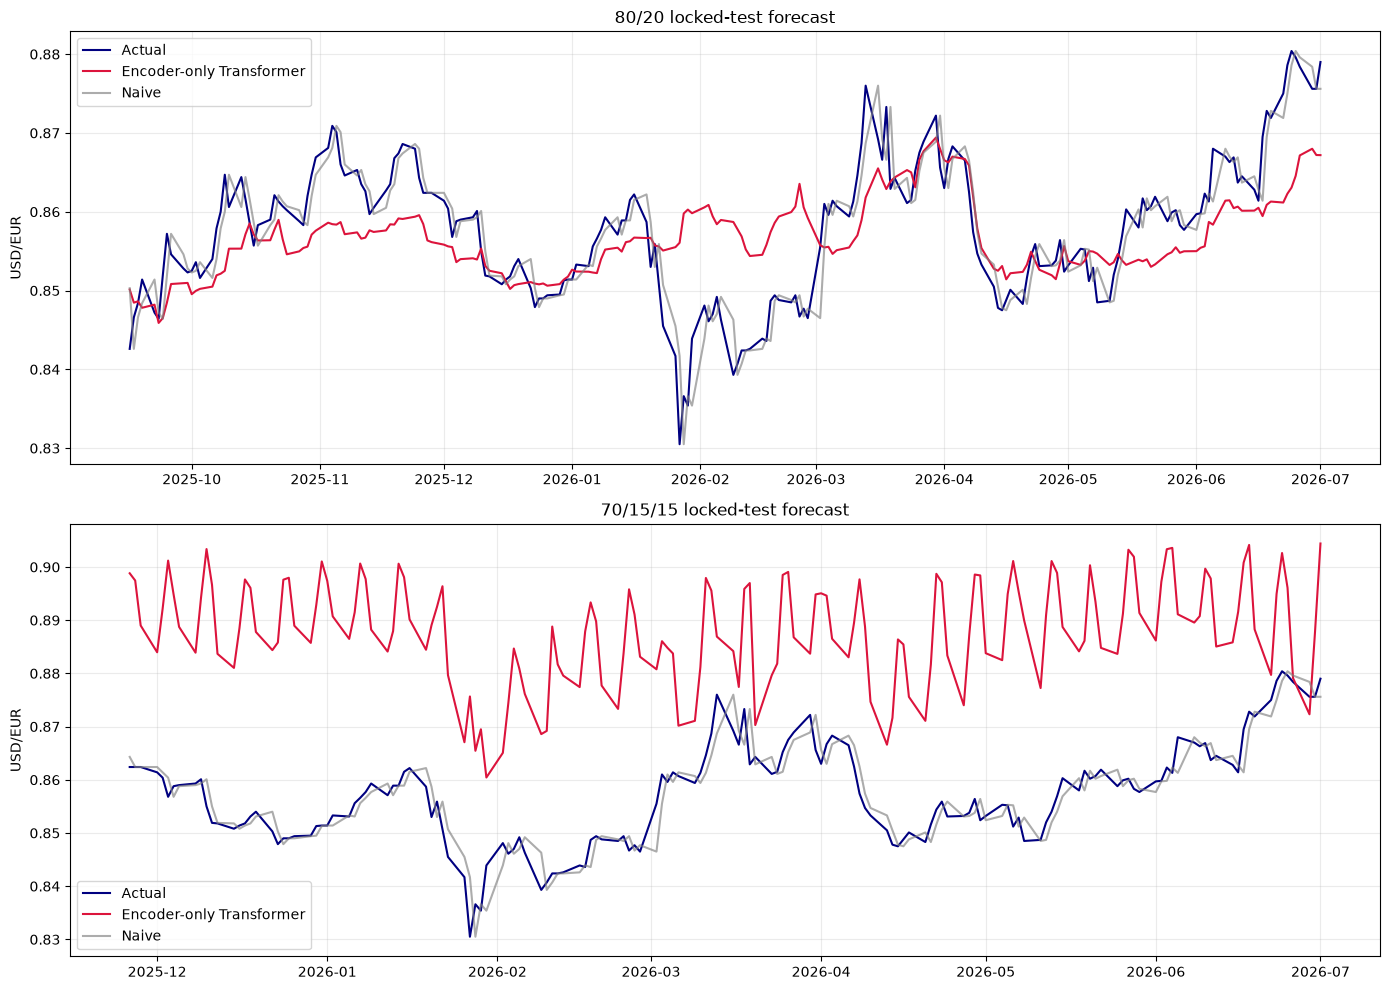

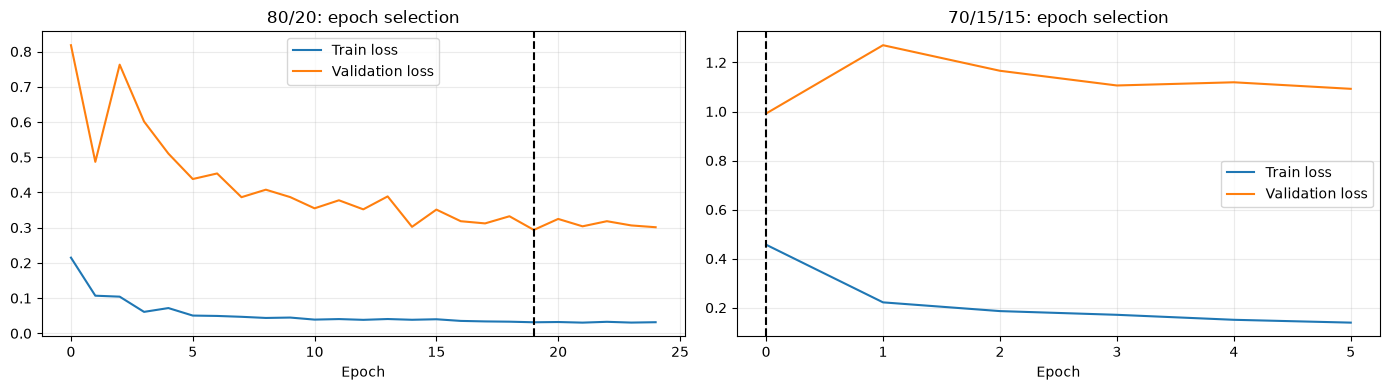

In [12]:
fig, axes = plt.subplots(2, 1, figsize=(14, 10))
for ax, (strategy, result) in zip(axes, results.items()):
    ax.plot(result["dates"], result["actual"], label="Actual", color="navy")
    ax.plot(
        result["dates"],
        result["prediction"],
        label="Encoder-only Transformer",
        color="crimson",
    )
    ax.plot(
        result["dates"],
        result["naive_prediction"],
        label="Naive",
        color="gray",
        alpha=0.65,
    )
    ax.set_title(f"{strategy} locked-test forecast")
    ax.set_ylabel("USD/EUR")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, strategy, tuning in [
    (axes[0], "80/20", tuning_80),
    (axes[1], "70/15/15", tuning_70),
]:
    ax.plot(tuning["history"]["loss"], label="Train loss")
    ax.plot(tuning["history"]["val_loss"], label="Validation loss")
    ax.axvline(tuning["best_epoch"] - 1, color="black", linestyle="--")
    ax.set_title(f"{strategy}: epoch selection")
    ax.set_xlabel("Epoch")
    ax.legend()
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11) Residual Diagnostics

ตรวจ overfitting ratio, residual mean bias, Ljung–Box autocorrelation, Jarque–Bera และ ARCH โดย normality/ARCH เป็น diagnostics เพิ่มเติม ไม่ใช่ข้อบังคับของ point forecast


,Strategy,Overfit ratio,Overfit heuristic pass,Residual mean,Bias p-value,No mean bias pass,Ljung-Box p-value (lag 10),Residual independence pass,Jarque-Bera p-value,ARCH p-value
0,80/20,3.708433,False,0.001113,0.03168,False,0.0,False,0.00000,0.0
1,70/15/15,2.316677,False,-0.030995,0.00000,False,0.0,False,0.03403,0.0


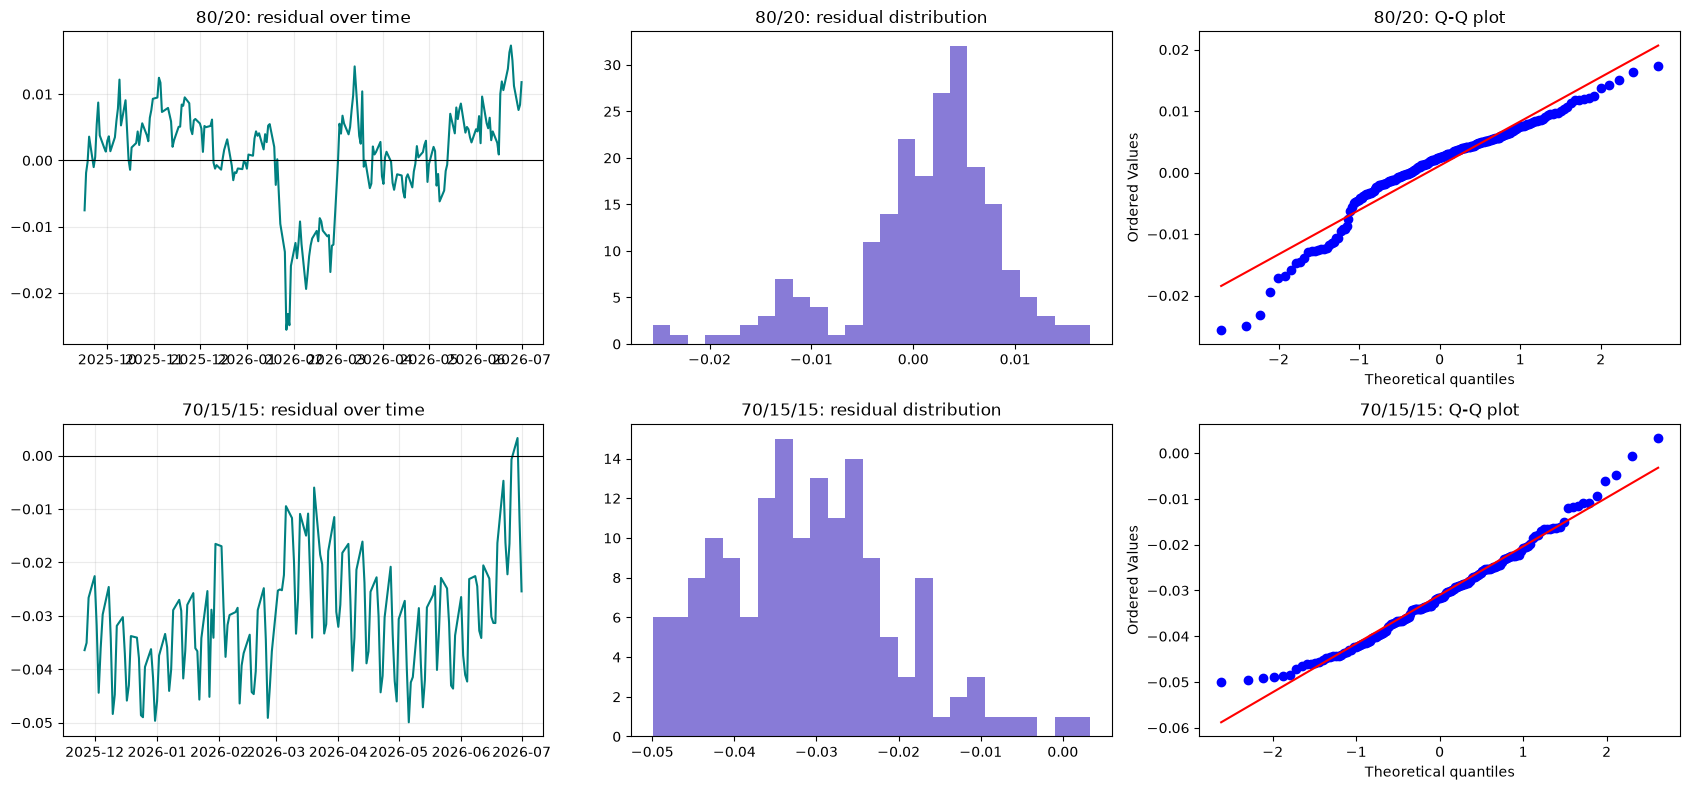

In [13]:
def transformer_diagnostics(strategy, result, overfit_ratio):
    residuals = result["actual"] - result["prediction"]
    diagnostic_lag = min(10, max(1, len(residuals) // 5))
    bias_test = stats.ttest_1samp(residuals, popmean=0.0)
    ljung_box = acorr_ljungbox(
        residuals,
        lags=[diagnostic_lag],
        return_df=True,
    ).iloc[0]
    jarque_bera = stats.jarque_bera(residuals)
    _, arch_pvalue, _, _ = het_arch(residuals, nlags=diagnostic_lag)
    return (
        {
            "Strategy": strategy,
            "Overfit ratio": overfit_ratio,
            "Overfit heuristic pass": overfit_ratio <= 1.5,
            "Residual mean": residuals.mean(),
            "Bias p-value": bias_test.pvalue,
            "No mean bias pass": bias_test.pvalue > 0.05,
            f"Ljung-Box p-value (lag {diagnostic_lag})": ljung_box["lb_pvalue"],
            "Residual independence pass": ljung_box["lb_pvalue"] > 0.05,
            "Jarque-Bera p-value": jarque_bera.pvalue,
            "ARCH p-value": arch_pvalue,
        },
        residuals,
    )


overfit_ratio_80 = tuning_80["validation_RMSE"] / tuning_80["train_RMSE"]
overfit_ratio_70 = tuning_70["validation_RMSE"] / tuning_70["train_RMSE"]
diagnostic_80, residuals_80 = transformer_diagnostics(
    "80/20", result_80, overfit_ratio_80
)
diagnostic_70, residuals_70 = transformer_diagnostics(
    "70/15/15", result_70, overfit_ratio_70
)
diagnostics = pd.DataFrame([diagnostic_80, diagnostic_70])
display(diagnostics.round(6))

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for row, (strategy, result, residuals) in enumerate(
    [
        ("80/20", result_80, residuals_80),
        ("70/15/15", result_70, residuals_70),
    ]
):
    axes[row, 0].plot(result["dates"], residuals, color="teal")
    axes[row, 0].axhline(0, color="black", linewidth=0.8)
    axes[row, 0].set_title(f"{strategy}: residual over time")
    axes[row, 0].grid(alpha=0.25)
    axes[row, 1].hist(residuals, bins=25, color="slateblue", alpha=0.8)
    axes[row, 1].set_title(f"{strategy}: residual distribution")
    stats.probplot(residuals, dist="norm", plot=axes[row, 2])
    axes[row, 2].set_title(f"{strategy}: Q-Q plot")
plt.tight_layout()
plt.show()

## 12) Attention Inspection

แสดง attention matrix ของ Encoder block สุดท้ายสำหรับ sample สุดท้ายใน Test โดยใช้เพื่อสำรวจเท่านั้น ไม่ถือเป็นหลักฐานเชิงเหตุและผลหรือ feature importance โดยตรง


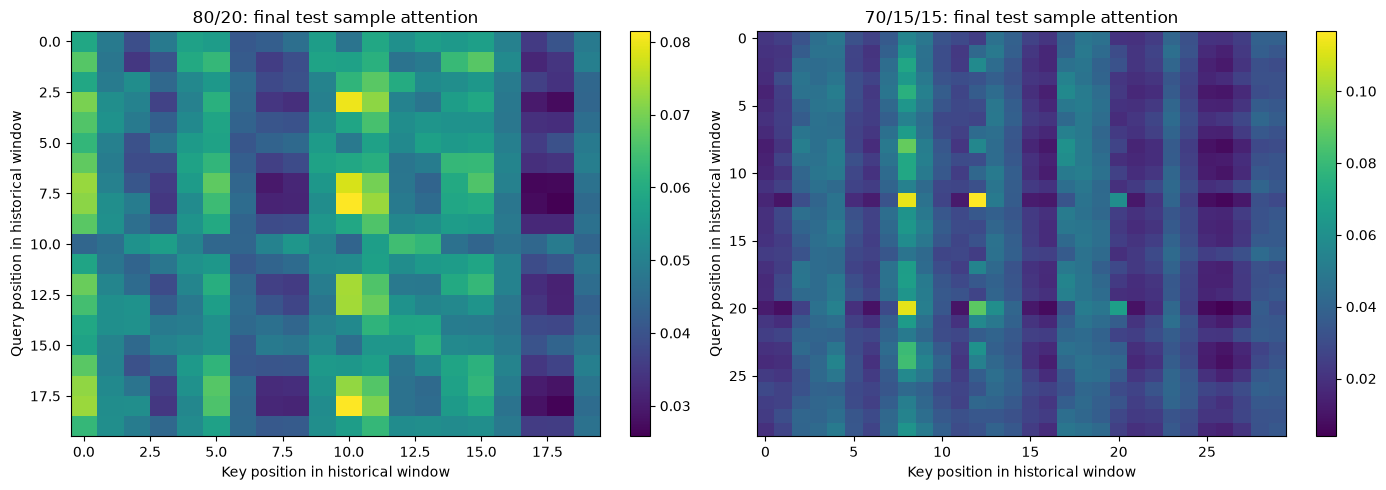

Attention is an inspection aid, not proof of causal feature importance. Every token shown is historical relative to the forecast target.


In [14]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, (strategy, result) in zip(axes, results.items()):
    attention = result["attention_model"].predict(
        result["test_X_scaled"][-1:],
        verbose=0,
    )[0]
    mean_attention = attention.mean(axis=0)
    image = ax.imshow(mean_attention, aspect="auto", cmap="viridis")
    ax.set_title(f"{strategy}: final test sample attention")
    ax.set_xlabel("Key position in historical window")
    ax.set_ylabel("Query position in historical window")
    fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()
print(
    "Attention is an inspection aid, not proof of causal feature importance. "
    "Every token shown is historical relative to the forecast target."
)

## 13) Final Model และ Next-observation Forecast

Fit โมเดลใหม่ด้วยข้อมูลทั้งหมดและจำนวน epochs ที่เลือกไว้ แล้วใช้ sequence ล่าสุดพยากรณ์ observation ถัดไป วันที่ใช้วันทำการถัดไปเป็นตัวแทนและอาจไม่ตรงวันเปิดตลาดจริงเมื่อมีวันหยุดพิเศษ


In [15]:
def fit_all_and_forecast_next(feature_frame, config, epochs, seed):
    X, y, _, _ = make_sequences(feature_frame, config["lookback"])
    x_scaler, y_scaler = fit_scalers(X, y)
    X_scaled = transform_X(X, x_scaler)
    y_scaled = y_scaler.transform(y.reshape(-1, 1)).reshape(-1)

    keras.backend.clear_session()
    reset_seeds(seed)
    model, _ = build_encoder_model(config, X.shape[-1])
    model.fit(
        X_scaled,
        y_scaled,
        epochs=max(1, int(epochs)),
        batch_size=config["batch_size"],
        shuffle=False,
        verbose=0,
    )

    next_sequence = feature_frame[FEATURE_COLUMNS].iloc[
        -config["lookback"]:
    ].to_numpy(dtype=np.float32)[None, :, :]
    next_scaled = transform_X(next_sequence, x_scaler)
    forecast_scaled = model.predict(next_scaled, verbose=0)
    forecast = float(inverse_y(forecast_scaled, y_scaler)[0])
    next_date = feature_frame.index.max() + pd.offsets.BDay(1)
    return model, next_date, forecast


final_model_80, next_date_80, forecast_80 = fit_all_and_forecast_next(
    feature_frame,
    BEST_CONFIG_80,
    tuning_80["best_epoch"],
    seed=SEED + 1000,
)
final_model_70, next_date_70, forecast_70 = fit_all_and_forecast_next(
    feature_frame,
    BEST_CONFIG_70,
    tuning_70["best_epoch"],
    seed=SEED + 1050,
)

final_forecasts = pd.DataFrame(
    [
        {
            "Strategy source": "80/20 CV winner",
            "Last observed date": feature_frame.index.max().date(),
            "Forecast date proxy": next_date_80.date(),
            "Last actual price": feature_frame["Price"].iloc[-1],
            "Forecast price": forecast_80,
            "Epochs": tuning_80["best_epoch"],
            **BEST_CONFIG_80,
        },
        {
            "Strategy source": "70/15/15 validation winner",
            "Last observed date": feature_frame.index.max().date(),
            "Forecast date proxy": next_date_70.date(),
            "Last actual price": feature_frame["Price"].iloc[-1],
            "Forecast price": forecast_70,
            "Epochs": tuning_70["best_epoch"],
            **BEST_CONFIG_70,
        },
    ]
)
display(final_forecasts.round(6))

transformer_rows = comparison.loc[
    comparison["Model"] == "Encoder-only Transformer"
]
best_test_row = transformer_rows.sort_values("MAPE (%)").iloc[0]
print("=" * 72)
print("ENCODER-ONLY TRANSFORMER EVALUATION SUMMARY")
print("=" * 72)
print(f"Lowest test MAPE strategy: {best_test_row['Strategy']}")
print(f"Test MAPE: {best_test_row['MAPE (%)']:.4f}%")
print(f"Test RMSE: {best_test_row['RMSE']:.6f}")
print(
    "RMSE better than naive: "
    f"{best_test_row['RMSE better than naive (%)']:.2f}%"
)
print(
    "Directional accuracy: "
    f"{best_test_row['Directional accuracy (%)']:.2f}%"
)
if best_test_row["RMSE better than naive (%)"] > 0:
    print("Conclusion: Encoder-only Transformer beats naive on this test period.")
else:
    print(
        "Conclusion: Encoder-only Transformer does not beat naive; "
        "do not promote it to production."
    )
if not diagnostics[
    ["Overfit heuristic pass", "No mean bias pass", "Residual independence pass"]
].all(axis=None):
    print("Diagnostics warning: at least one split fails a diagnostic check.")
print("Decoder layers used: 0")
print("Final forecast is a model estimate, not trading advice.")

,Strategy source,Last observed date,Forecast date proxy,Last actual price,Forecast price,Epochs,lookback,d_model,num_heads,ff_dim,num_blocks,dropout,pooling,learning_rate,batch_size
0,80/20 CV winner,2026-07-01,2026-07-02,0.879,0.876876,20,20,32,4,64,1,0.1,average,0.0005,32
1,70/15/15 validation winner,2026-07-01,2026-07-02,0.879,0.863446,1,30,16,2,32,1,0.1,last,0.0010,32


ENCODER-ONLY TRANSFORMER EVALUATION SUMMARY
Lowest test MAPE strategy: 80/20
Test MAPE: 0.6676%
Test RMSE: 0.007470
RMSE better than naive: -142.08%
Directional accuracy: 53.14%
Conclusion: Encoder-only Transformer does not beat naive; do not promote it to production.
Diagnostics warning: at least one split fails a diagnostic check.
Decoder layers used: 0
Final forecast is a model estimate, not trading advice.


## เกณฑ์การอ่านผล

1. Test MAE, RMSE, MAPE และ sMAPE ยิ่งต่ำยิ่งดี
2. `RMSE better than naive (%)` ต้องเป็นค่าบวกจึงจะชนะ baseline
3. Directional Accuracy สูงกว่า 50% แปลว่าจับทิศทางได้ดีกว่าการเดาสุ่มเชิงสัญญาณ
4. CV error และความแปรปรวนระหว่าง folds ควรต่ำ
5. Overfit ratio ไม่ควรสูง และ residual ไม่ควรมี bias/autocorrelation
6. 80/20 และ 70/15/15 มี Test period ต่างกัน จึงต้องอ่านช่วงวันที่ร่วมกับ metrics
7. Forecast เป็น model estimate ไม่ใช่คำแนะนำซื้อขาย
